# Final comparison: MMLU vs MixInstruct (multi-seed RL and bandit algorithms)

Reads the two result files written by `05_multiseed_bandits_*.ipynb` (`ms_mmlu_results.json` and `ms_mixinstruct_results.json`, from the
real runs, not the dry runs) and puts them side by side. No GPU, no models: it only reads those files, so it runs in seconds.

It answers four questions:
1. How much do results vary across seeds, on each dataset?
2. Does routing beat the best single model, on each dataset?
3. Does a different exploration rule beat epsilon-greedy (Stage A: many seeds, frozen features; Stage B: few seeds, fine-tuned)?
4. Do the two datasets agree?

**What this does not cover:** HybridLLM and the FrugalGPT cascade were not repeated over seeds, so they are not in these tables.
"Utility" is `(+1 / -1 satisfaction) - lambda_eval * cost` with a fixed lambda_eval, the same for every method.

In [1]:
import os, json
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = os.path.expanduser("~/hybridllm_project/outputs")
R = {}
for ds in ("mmlu", "mixinstruct"):
    path = os.path.join(OUTPUT_DIR, f"ms_{ds}_results.json")
    if not os.path.exists(path):
        raise FileNotFoundError(f"missing {path}: run 05_multiseed_bandits_*.ipynb with DATASET = '{ds}' and DRY_RUN = False first")
    R[ds] = json.load(open(path))
    assert not R[ds]["dry_run"], f"{path} comes from a dry run"
    print(f"{ds}: {R[ds]['n_stream']} training questions, {R[ds]['n_test']} test questions, {R[ds]['n_seeds_stage_a']} Stage A seeds, "
          f"fine-tuned seeds {R[ds]['ft_seeds']}, lambda_eval {R[ds]['lambda_eval']}")
sd = lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else 0.0

mmlu: 12542 training questions, 1531 test questions, 20 Stage A seeds, fine-tuned seeds [0, 1, 2], lambda_eval 0.5
mixinstruct: 9000 training questions, 1500 test questions, 20 Stage A seeds, fine-tuned seeds [0, 1, 2], lambda_eval 0.5


## 1. The single-model baselines

In [2]:
for ds, r in R.items():
    print(f"\n=== {ds} (quality = {r['quality_label']}) ===")
    print(f"{'model':>16} {'cost':>6} {'test quality':>13} {'test utility':>13}")
    for n in r["model_names"]:
        e = r["fixed_test"][n]
        print(f"{n:>16} {r['costs'][r['model_names'].index(n)]:6.3f} {100*e['acc']:12.1f}% {e['util']:+13.3f}" + ("   <- best on validation" if n == r["best_fixed"] else ""))


=== mmlu (quality = accuracy) ===
           model   cost  test quality  test utility
   flan-t5-small  0.011         29.3%        -0.419
    flan-t5-base  0.036         33.4%        -0.349
   flan-t5-large  0.111         42.0%        -0.216   <- best on validation
      flan-t5-xl  0.429         49.8%        -0.218
 llama-2-7b-chat  1.000         45.6%        -0.588

=== mixinstruct (quality = pass rate) ===
           model   cost  test quality  test utility
   flan-t5-small  0.011         53.1%        +0.056
    flan-t5-base  0.036         50.1%        -0.015
   flan-t5-large  0.111         50.0%        -0.056
      flan-t5-xl  0.429         57.8%        -0.058
 llama-2-7b-chat  1.000         90.9%        +0.319   <- best on validation


## 2. Stage A: bandit algorithms, frozen features, many seeds

Per algorithm, lambda was chosen on validation. The last column is the difference in test utility between the bandit and the best
single model, with a 95% bootstrap interval over seeds: an interval above zero means routing beats that single model.

In [3]:
def fmt_ci(ci): d, lo, hi = ci; return f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]  " + ("better" if lo > 0 else ("worse" if hi < 0 else "n.s."))
for ds, r in R.items():
    print(f"\n=== {ds}: {r['n_seeds_stage_a']} seeds, best single model = {r['best_fixed']} "
          f"(test utility {r['fixed_test'][r['best_fixed']]['util']:+.3f}) ===")
    print(f"{'algorithm':>16} {'lam':>5} {'test '+r['quality_label']+' %':>16} {'test cost':>14} {'test utility':>16} {'vs best single model':>40}")
    for a, m in r["stage_a"].items():
        print(f"{a:>16} {m['lambda']:5} {100*np.mean(m['test_acc']):9.1f} +- {100*sd(m['test_acc']):4.1f} "
              f"{np.mean(m['test_cost']):7.3f} +- {sd(m['test_cost']):.3f} {np.mean(m['test_util']):+9.3f} +- {sd(m['test_util']):.3f}   {fmt_ci(m['diff_vs_best_fixed'])}")


=== mmlu: 20 seeds, best single model = flan-t5-large (test utility -0.216) ===
       algorithm   lam  test accuracy %      test cost     test utility                     vs best single model
     egreedy-mlp   0.5      46.0 +-  2.2   0.234 +- 0.068    -0.198 +- 0.024   +0.018 [+0.007, +0.028]  better
   boltzmann-mlp   0.5      46.3 +-  2.4   0.233 +- 0.073    -0.191 +- 0.024   +0.025 [+0.015, +0.035]  better
  egreedy-linear   0.5      46.0 +-  0.8   0.234 +- 0.015    -0.196 +- 0.014   +0.019 [+0.014, +0.025]  better
    linucb a=0.1   0.5      46.6 +-  1.1   0.236 +- 0.033    -0.186 +- 0.011   +0.030 [+0.025, +0.035]  better
    linucb a=0.5   0.5      46.1 +-  1.2   0.234 +- 0.030    -0.195 +- 0.014   +0.020 [+0.014, +0.027]  better
     linTS v=0.1   0.5      45.9 +-  1.6   0.228 +- 0.042    -0.196 +- 0.016   +0.019 [+0.013, +0.027]  better
     linTS v=0.5   0.5      46.1 +-  0.7   0.237 +- 0.014    -0.195 +- 0.012   +0.020 [+0.015, +0.025]  better

=== mixinstruct: 20 seeds, b

## 3. Stage B: the fine-tuned RL, epsilon-greedy vs Boltzmann

Few seeds, so read the per-seed values, not just the mean. `*` marks the lambda chosen on validation for that algorithm.

In [4]:
for ds, r in R.items():
    print(f"\n=== {ds}: fine-tuned RL, seeds {r['ft_seeds']} ===")
    if not r["stage_b"]:
        print("  (Stage B was not run)"); continue
    fx = r["fixed_test"][r["best_fixed"]]["util"]
    print(f"{'algo':>6} {'lam':>5} {'val util':>9} {'test '+r['quality_label']+' %':>14} {'test cost':>12} {'test utility':>16} {'minus best single model, per seed':>40}")
    for key, m in r["stage_b"].items():
        algo, lam = key.split("|"); star = "*" if str(r["stage_b_selected_lambda"][algo]) == lam else " "
        print(f"{algo:>6} {lam:>4}{star} {m['val_util']:+9.3f} {100*np.mean(m['acc']):8.1f} +- {100*sd(m['acc']):3.1f} {np.mean(m['cost']):6.3f} +- {sd(m['cost']):.3f} "
              f"{np.mean(m['util']):+9.3f} +- {sd(m['util']):.3f}   " + " ".join(f"{u - fx:+.3f}" for u in m["util"]))


=== mmlu: fine-tuned RL, seeds [0, 1, 2] ===
  algo   lam  val util test accuracy %    test cost     test utility        minus best single model, per seed
   eps 0.25     -0.259     49.1 +- 1.2  0.387 +- 0.059    -0.211 +- 0.007   +0.013 +0.005 -0.002
   eps  0.5*    -0.240     41.5 +- 0.9  0.102 +- 0.017    -0.222 +- 0.010   +0.000 +0.000 -0.018
 boltz 0.25*    -0.246     46.3 +- 3.9  0.226 +- 0.105    -0.187 +- 0.025   +0.047 +0.000 +0.040
 boltz  0.5     -0.262     47.2 +- 4.5  0.323 +- 0.183    -0.217 +- 0.002   -0.002 +0.001 -0.002

=== mixinstruct: fine-tuned RL, seeds [0, 1, 2] ===
  algo   lam  val util test pass rate %    test cost     test utility        minus best single model, per seed
   eps  0.5     +0.432     88.2 +- 2.0  0.723 +- 0.163    +0.403 +- 0.045   +0.082 +0.040 +0.131
   eps  1.0*    +0.448     82.1 +- 3.1  0.438 +- 0.069    +0.422 +- 0.029   +0.120 +0.120 +0.070
 boltz  0.5*    +0.483     89.2 +- 0.7  0.643 +- 0.013    +0.464 +- 0.008   +0.149 +0.149 +0.136
 

## 4. Plots

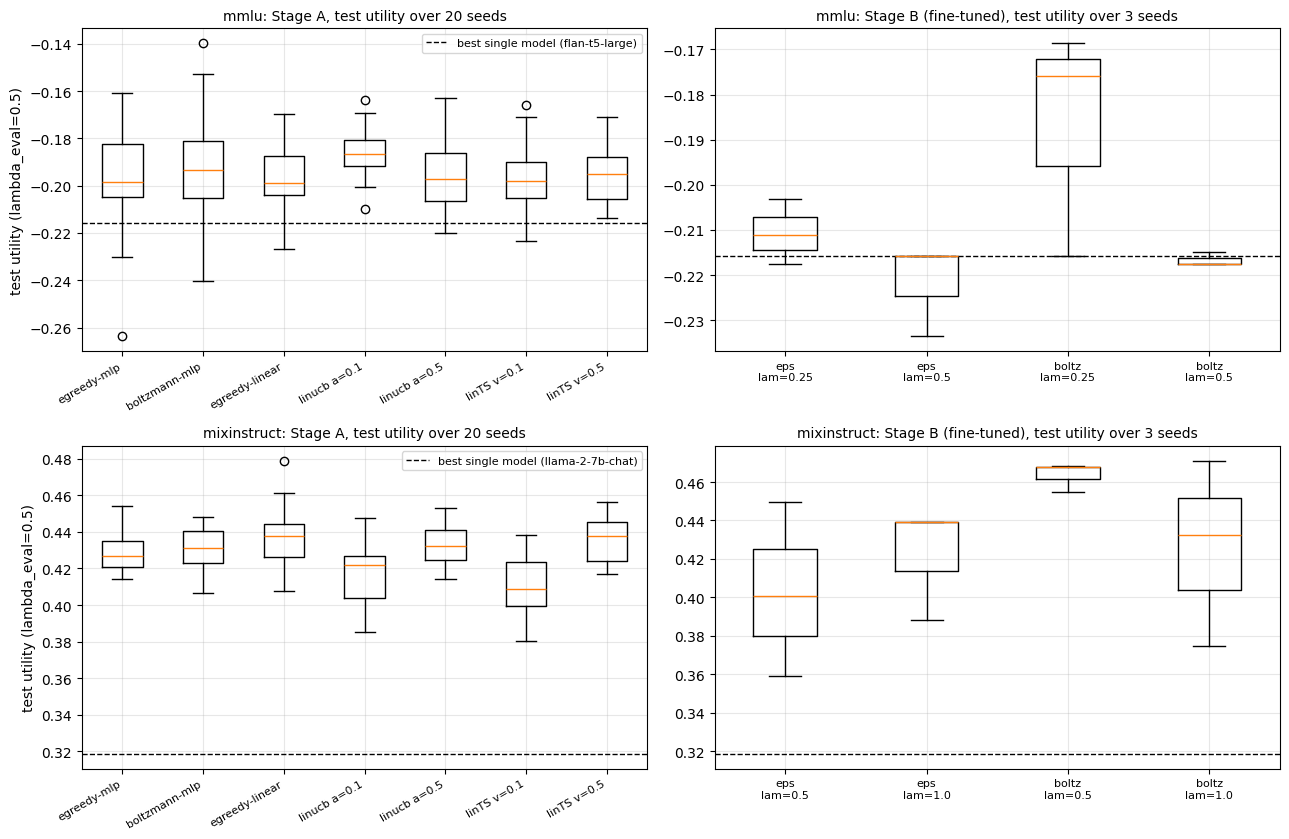

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for row, (ds, r) in enumerate(R.items()):
    ax = axes[row][0]; names = list(r["stage_a"])
    ax.boxplot([r["stage_a"][a]["test_util"] for a in names])
    ax.axhline(r["fixed_test"][r["best_fixed"]]["util"], color="k", ls="--", lw=1, label=f"best single model ({r['best_fixed']})")
    ax.set_xticks(range(1, len(names) + 1)); ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)
    ax.set_title(f"{ds}: Stage A, test utility over {r['n_seeds_stage_a']} seeds", fontsize=10); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.set_ylabel(f"test utility (lambda_eval={r['lambda_eval']})")
    ax = axes[row][1]
    if r["stage_b"]:
        keys = list(r["stage_b"]); ax.boxplot([r["stage_b"][k]["util"] for k in keys])
        ax.axhline(r["fixed_test"][r["best_fixed"]]["util"], color="k", ls="--", lw=1)
        ax.set_xticks(range(1, len(keys) + 1)); ax.set_xticklabels([k.replace("|", "\nlam=") for k in keys], fontsize=8)
        ax.set_title(f"{ds}: Stage B (fine-tuned), test utility over {len(r['ft_seeds'])} seeds", fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "ms_final_comparison.png"), dpi=150); plt.show()

## 5. Cross-dataset summary

Algorithm choice here follows the same rule as before: for each dataset, pick the algorithm with the highest **validation** utility,
then report its test result. The rank table is descriptive only (it ranks on test utility), so do not use it to select anything.

In [6]:
print("Best Stage A algorithm per dataset, chosen on validation:")
for ds, r in R.items():
    a = max(r["stage_a"], key=lambda k: r["stage_a"][k]["val_util"]); m = r["stage_a"][a]
    print(f"  {ds:>12}: {a} (lambda={m['lambda']}): test utility {np.mean(m['test_util']):+.3f} +- {sd(m['test_util']):.3f}; "
          f"vs best single model {r['best_fixed']}: {fmt_ci(m['diff_vs_best_fixed'])}")

algos = list(R["mmlu"]["stage_a"])
ranks = {a: [] for a in algos}
for ds, r in R.items():
    order = sorted(algos, key=lambda a: -np.mean(r["stage_a"][a]["test_util"]))
    for pos, a in enumerate(order): ranks[a].append(pos + 1)
print(f"\nDescriptive rank by mean test utility (1 = best), per dataset:")
print(f"{'algorithm':>16} {'mmlu':>6} {'mixinstruct':>12} {'mean rank':>10}")
for a in sorted(algos, key=lambda a: np.mean(ranks[a])): print(f"{a:>16} {ranks[a][0]:6d} {ranks[a][1]:12d} {np.mean(ranks[a]):10.1f}")

print("\nSeed-to-seed variation (sd of test utility) of the reference algorithm, " + R["mmlu"]["reference_algo"] + ":")
for ds, r in R.items():
    print(f"  {ds:>12}: sd {sd(r['stage_a'][r['reference_algo']]['test_util']):.3f} over {r['n_seeds_stage_a']} seeds")

print("\nIs any alternative distinguishable from the reference algorithm (paired over seeds, 95% interval)?")
for ds, r in R.items():
    hits = [(a, m["paired_diff_vs_reference"]) for a, m in r["stage_a"].items() if a != r["reference_algo"]]
    better = [a for a, (d, lo, hi) in hits if lo > 0]; worse = [a for a, (d, lo, hi) in hits if hi < 0]
    print(f"  {ds:>12}: better than reference: {better or 'none'}; worse: {worse or 'none'}")

Best Stage A algorithm per dataset, chosen on validation:
          mmlu: linucb a=0.5 (lambda=0.5): test utility -0.195 +- 0.014; vs best single model flan-t5-large: +0.020 [+0.014, +0.027]  better
   mixinstruct: linTS v=0.5 (lambda=0.5): test utility +0.437 +- 0.012; vs best single model llama-2-7b-chat: +0.118 [+0.113, +0.123]  better

Descriptive rank by mean test utility (1 = best), per dataset:
       algorithm   mmlu  mixinstruct  mean rank
   boltzmann-mlp      2            4        3.0
    linucb a=0.5      3            3        3.0
     linTS v=0.5      4            2        3.0
  egreedy-linear      6            1        3.5
    linucb a=0.1      1            6        3.5
     egreedy-mlp      7            5        6.0
     linTS v=0.1      5            7        6.0

Seed-to-seed variation (sd of test utility) of the reference algorithm, egreedy-mlp:
          mmlu: sd 0.024 over 20 seeds
   mixinstruct: sd 0.010 over 20 seeds

Is any alternative distinguishable from the re

## 6. Auto-generated reading of the results

These sentences are generated from the numbers above, with the same significance rule everywhere (95% interval excludes zero).
Check each against the tables before you use it, and add the caveats below.

In [7]:
lines = []
for ds, r in R.items():
    a = max(r["stage_a"], key=lambda k: r["stage_a"][k]["val_util"]); m = r["stage_a"][a]; d, lo, hi = m["diff_vs_best_fixed"]
    verdict = "beats" if lo > 0 else ("is worse than" if hi < 0 else "is not distinguishable from")
    lines.append(f"{ds}: the best single model is {r['best_fixed']}. The bandit chosen on validation ({a}, lambda={m['lambda']}) {verdict} it "
                 f"on test utility ({d:+.3f}, 95% interval [{lo:+.3f}, {hi:+.3f}] over {r['n_seeds_stage_a']} seeds).")
    ref = r["stage_a"][r["reference_algo"]]
    lines.append(f"{ds}: epsilon-greedy with frozen features varies by +-{sd(ref['test_util']):.3f} (sd of test utility) across seeds.")
    if r["stage_b"]:
        for algo in r["ft_algos"]:
            lam = r["stage_b_selected_lambda"][algo]; u = r["stage_b"][f"{algo}|{lam}"]["util"]
            lines.append(f"{ds}: fine-tuned {algo} (lambda={lam}) test utility {np.mean(u):+.3f}, per-seed range [{min(u):+.3f}, {max(u):+.3f}] over {len(u)} seeds.")
print("\n".join("- " + l for l in lines))
print("""
Caveats to state with these results:
- Stage A uses frozen features and a 64-dimension projection: it screens algorithms but is not the fine-tuned system.
- Stage B has few seeds, so its per-seed spread is the honest summary, not a confidence interval.
- Lambda and bandit parameters were chosen on a validation split, but only over small grids.
- The reward is read from a table of precomputed answers: a real deployment would need a feedback signal.
- HybridLLM and the FrugalGPT cascade were not repeated over seeds here.""")

- mmlu: the best single model is flan-t5-large. The bandit chosen on validation (linucb a=0.5, lambda=0.5) beats it on test utility (+0.020, 95% interval [+0.014, +0.027] over 20 seeds).
- mmlu: epsilon-greedy with frozen features varies by +-0.024 (sd of test utility) across seeds.
- mmlu: fine-tuned eps (lambda=0.5) test utility -0.222, per-seed range [-0.234, -0.216] over 3 seeds.
- mmlu: fine-tuned boltz (lambda=0.25) test utility -0.187, per-seed range [-0.216, -0.169] over 3 seeds.
- mixinstruct: the best single model is llama-2-7b-chat. The bandit chosen on validation (linTS v=0.5, lambda=0.5) beats it on test utility (+0.118, 95% interval [+0.113, +0.123] over 20 seeds).
- mixinstruct: epsilon-greedy with frozen features varies by +-0.010 (sd of test utility) across seeds.
- mixinstruct: fine-tuned eps (lambda=1.0) test utility +0.422, per-seed range [+0.388, +0.439] over 3 seeds.
- mixinstruct: fine-tuned boltz (lambda=0.5) test utility +0.464, per-seed range [+0.455, +0.468] 